# SMS Spam Classifier - Stage 1 & 2: Ingestion & Exploratory Data Analysis

This notebook covers:
- Loading and preprocessing the raw SMS Spam Collection dataset (`data/spam.csv`)
- Dataset shape, preview, class counts, and duplicate row detection
- Exploratory visualizations: class balance countplot, message length distribution by class, and word clouds

## 1. Imports and Setup

In [18]:
# Import required libraries for data handling and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

# Configure visualization settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["font.size"] = 11

## 2. Load and Prepare Dataset

In [19]:
# Load the dataset with latin-1 encoding, keep only relevant columns (v1, v2), and rename them
df = pd.read_csv('data/spam.csv', encoding='latin-1')
df = df[['v1', 'v2']].rename(columns={'v1': 'label', 'v2': 'text'})

## 3. Dataset Summary and Duplicate Reporting

In [20]:
# Print dataset shape, first 5 rows, class distribution counts, and total duplicate rows
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns\n")

print("--- First 5 Rows ---")
display(df.head())

print("\n--- Class Counts ---")
class_counts = df['label'].value_counts()
print(class_counts)

print(f"\nClass Percentages:\n{df['label'].value_counts(normalize=True).mul(100).round(2)}%")

duplicate_count = df.duplicated().sum()
print(f"\nNumber of duplicate rows: {duplicate_count}")

Dataset Shape: 5572 rows, 2 columns

--- First 5 Rows ---


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."



--- Class Counts ---
label
ham     4825
spam     747
Name: count, dtype: int64

Class Percentages:
label
ham     86.59
spam    13.41
Name: proportion, dtype: float64%

Number of duplicate rows: 403


## 4. Data Visualizations

### 4.1 Class Balance Countplot

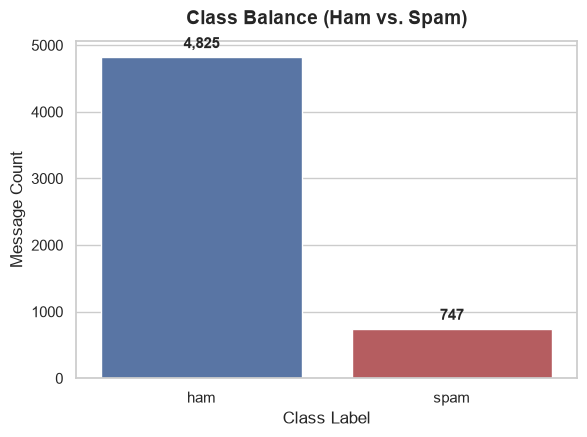

In [21]:
# Plot the distribution of classes (ham vs spam) to visualize class balance
plt.figure(figsize=(6, 4.5))
ax = sns.countplot(
    data=df,
    x='label',
    hue='label',
    palette={'ham': '#4C72B0', 'spam': '#C44E52'},
    legend=False
)
plt.title('Class Balance (Ham vs. Spam)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Class Label', fontsize=12)
plt.ylabel('Message Count', fontsize=12)

# Add count labels on top of each bar
for p in ax.patches:
    height = int(p.get_height())
    ax.annotate(
        f"{height:,}",
        (p.get_x() + p.get_width() / 2.0, height),
        ha='center',
        va='bottom',
        fontsize=11,
        fontweight='bold',
        xytext=(0, 4),
        textcoords='offset points'
    )

plt.tight_layout()
plt.show()

### 4.2 Message Length Histogram by Class

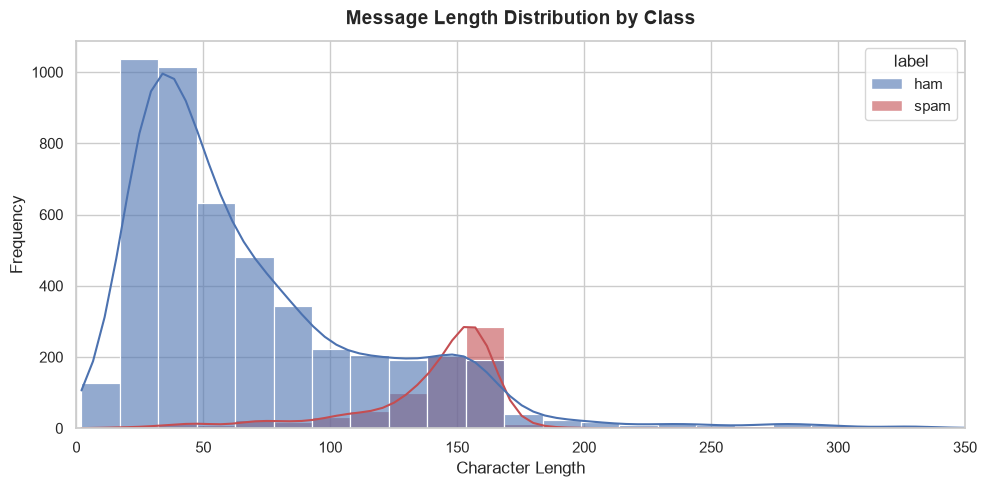

In [22]:
# Compute message character lengths and plot histograms comparing ham vs spam distributions
df['length'] = df['text'].astype(str).apply(len)

plt.figure(figsize=(10, 5))
sns.histplot(
    data=df,
    x='length',
    hue='label',
    bins=60,
    kde=True,
    palette={'ham': '#4C72B0', 'spam': '#C44E52'},
    alpha=0.6
)
plt.title('Message Length Distribution by Class', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Character Length', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.xlim(0, 350)
plt.tight_layout()
plt.show()

### 4.3 Word Clouds for Spam and Ham

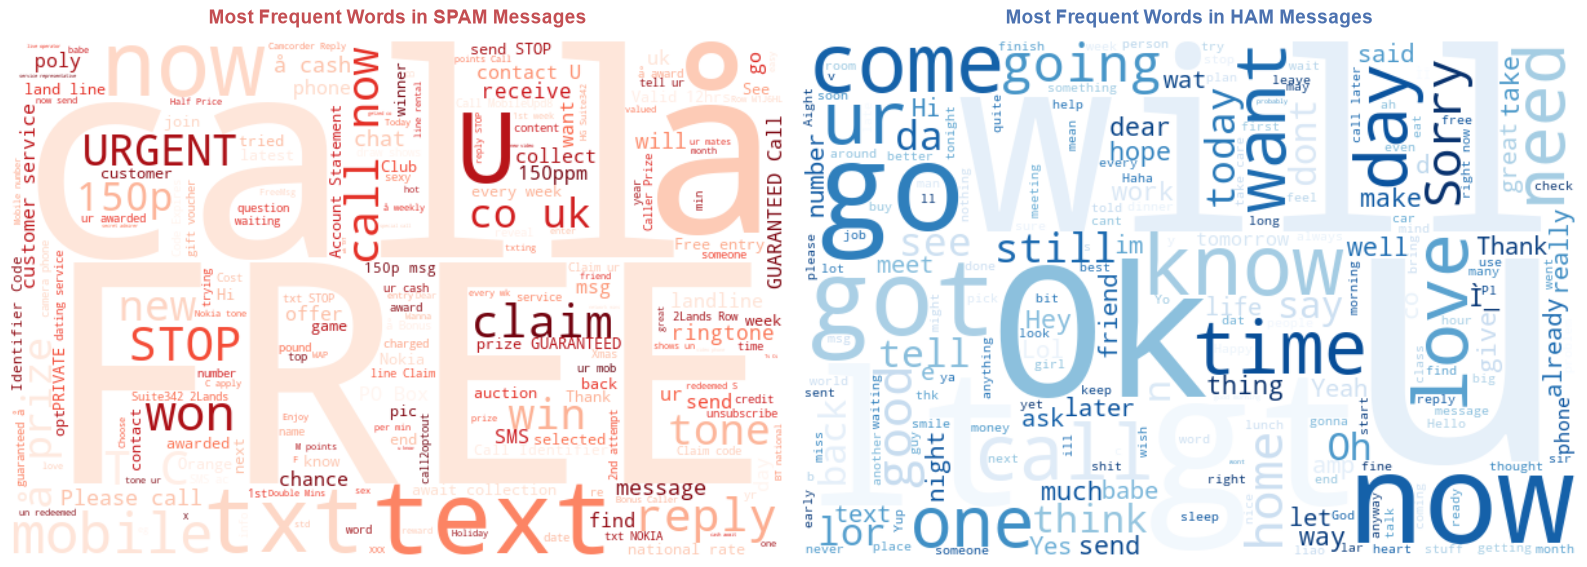

In [23]:
# Generate and display word clouds for spam and ham messages to highlight distinctive vocabulary
spam_text = ' '.join(df[df['label'] == 'spam']['text'].dropna().astype(str))
ham_text = ' '.join(df[df['label'] == 'ham']['text'].dropna().astype(str))

spam_wordcloud = WordCloud(
    width=600,
    height=400,
    background_color='white',
    colormap='Reds',
    random_state=42
).generate(spam_text)

ham_wordcloud = WordCloud(
    width=600,
    height=400,
    background_color='white',
    colormap='Blues',
    random_state=42
).generate(ham_text)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].imshow(spam_wordcloud, interpolation='bilinear')
axes[0].set_title('Most Frequent Words in SPAM Messages', fontsize=14, fontweight='bold', color='#C44E52', pad=12)
axes[0].axis('off')

axes[1].imshow(ham_wordcloud, interpolation='bilinear')
axes[1].set_title('Most Frequent Words in HAM Messages', fontsize=14, fontweight='bold', color='#4C72B0', pad=12)
axes[1].axis('off')

plt.tight_layout()
plt.show()

## 5. Data Preprocessing

### 5.1 Remove Duplicate Rows

In [24]:
# Remove duplicate records from the dataset and compare row counts before and after
rows_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
rows_after = len(df)

print(f"Row count before removing duplicates: {rows_before}")
print(f"Row count after removing duplicates:  {rows_after}")
print(f"Duplicate rows removed:               {rows_before - rows_after}")

Row count before removing duplicates: 5572
Row count after removing duplicates:  5169
Duplicate rows removed:               403


### 5.2 Encode Target Labels

In [25]:
# Add label_num column mapping 'ham' to 0 and 'spam' to 1
df['label_num'] = df['label'].map({'ham': 0, 'spam': 1})

print("Label encoding verification:")
display(df[['label', 'label_num']].drop_duplicates().reset_index(drop=True))

Label encoding verification:


,label,label_num
0,ham,0
1,spam,1


### 5.3 Text Cleaning & Stemming

In [26]:
# Define text cleaning function: lowercase, remove punctuation, remove stopwords, and apply Porter stemming
import string
import nltk
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer

# Ensure stopwords are available
nltk.download('stopwords', quiet=True)

stemmer = PorterStemmer()
stop_words = set(stopwords.words('english'))

def clean_text(text: str) -> str:
    # 1. Convert to lowercase
    text = text.lower()
    # 2. Remove punctuation
    text = text.translate(str.maketrans('', '', string.punctuation))
    # 3. Tokenize by whitespace
    words = text.split()
    # 4. Remove stopwords and stem remaining words
    stemmed_words = [stemmer.stem(word) for word in words if word not in stop_words]
    return ' '.join(stemmed_words)

# Apply text cleaning to all messages
df['cleaned_text'] = df['text'].apply(clean_text)

# Display 5 examples comparing before and after text cleaning
examples = df[['text', 'cleaned_text']].head(5)
for idx, row in examples.iterrows():
    print(f"Example {idx + 1}:")
    print(f"  Before: {row['text']}")
    print(f"  After:  {row['cleaned_text']}\n")

Example 1:
  Before: Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
  After:  go jurong point crazi avail bugi n great world la e buffet cine got amor wat

Example 2:
  Before: Ok lar... Joking wif u oni...
  After:  ok lar joke wif u oni

Example 3:
  Before: Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
  After:  free entri 2 wkli comp win fa cup final tkt 21st may 2005 text fa 87121 receiv entri questionstd txt ratetc appli 08452810075over18

Example 4:
  Before: U dun say so early hor... U c already then say...
  After:  u dun say earli hor u c alreadi say

Example 5:
  Before: Nah I don't think he goes to usf, he lives around here though
  After:  nah dont think goe usf live around though



## 6. Train-Test Split

In [27]:
# Split features and labels into train (80%) and test (20%) sets using stratified sampling
from sklearn.model_selection import train_test_split

X = df['cleaned_text']
y = df['label_num']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print(f"Training samples: {len(X_train)} ({len(X_train)/len(df):.1%})")
print(f"Testing samples:  {len(X_test)} ({len(X_test)/len(df):.1%})")
print("\nTrain class distribution:")
print(y_train.value_counts(normalize=True).round(4))
print("\nTest class distribution:")
print(y_test.value_counts(normalize=True).round(4))

Training samples: 4135 (80.0%)
Testing samples:  1034 (20.0%)

Train class distribution:
label_num
0    0.8738
1    0.1262
Name: proportion, dtype: float64

Test class distribution:
label_num
0    0.8733
1    0.1267
Name: proportion, dtype: float64


## 7. Feature Extraction with TF-IDF

In [28]:
# Convert text data to numerical features using TF-IDF, fitting only on the training set
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer()
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print(f"X_train_tfidf shape: {X_train_tfidf.shape}")
print(f"X_test_tfidf shape:  {X_test_tfidf.shape}")
print(f"Vocabulary size:     {len(tfidf.vocabulary_)} unique terms")

X_train_tfidf shape: (4135, 6959)
X_test_tfidf shape:  (1034, 6959)
Vocabulary size:     6959 unique terms


## 8. Model Training & Evaluation

We train and evaluate three baseline classifiers on `X_train_tfidf` and test on `X_test_tfidf`:
1. **Multinomial Naive Bayes (`MultinomialNB`)**
2. **Linear SVM (`LinearSVC`)**
3. **Logistic Regression (`LogisticRegression`)**

### 8.1 Multinomial Naive Bayes

=== Multinomial Naive Bayes ===
Accuracy:  0.9632
Precision: 0.9895 (Spam)
Recall:    0.7176 (Spam)
F1-Score:  0.8319 (Spam)



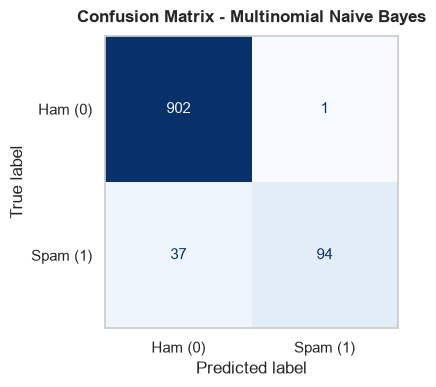

In [29]:
# Train Multinomial Naive Bayes, evaluate on test set, print metrics, and plot confusion matrix
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay

nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)
nb_preds = nb_model.predict(X_test_tfidf)

nb_metrics = {
    'Model': 'Multinomial Naive Bayes',
    'Accuracy': accuracy_score(y_test, nb_preds),
    'Precision': precision_score(y_test, nb_preds, pos_label=1),
    'Recall': recall_score(y_test, nb_preds, pos_label=1),
    'F1': f1_score(y_test, nb_preds, pos_label=1)
}

print(f"=== {nb_metrics['Model']} ===")
print(f"Accuracy:  {nb_metrics['Accuracy']:.4f}")
print(f"Precision: {nb_metrics['Precision']:.4f} (Spam)")
print(f"Recall:    {nb_metrics['Recall']:.4f} (Spam)")
print(f"F1-Score:  {nb_metrics['F1']:.4f} (Spam)\n")

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, nb_preds,
    display_labels=['Ham (0)', 'Spam (1)'],
    cmap='Blues',
    ax=ax,
    colorbar=False
)
plt.title('Confusion Matrix - Multinomial Naive Bayes', fontsize=12, fontweight='bold', pad=10)
plt.grid(False)
plt.tight_layout()
plt.show()

### 8.2 Linear SVM (LinearSVC)

=== Linear SVM (LinearSVC) ===
Accuracy:  0.9826
Precision: 0.9748 (Spam)
Recall:    0.8855 (Spam)
F1-Score:  0.9280 (Spam)



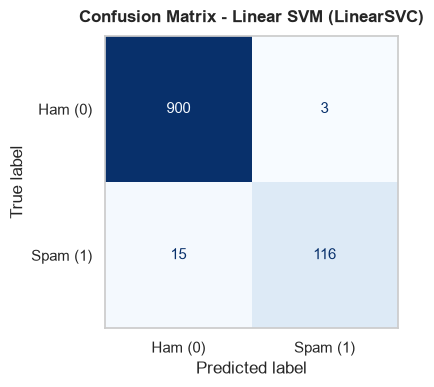

In [30]:
# Train Linear SVM (LinearSVC), evaluate on test set, print metrics, and plot confusion matrix
from sklearn.svm import LinearSVC

svm_model = LinearSVC(random_state=42)
svm_model.fit(X_train_tfidf, y_train)
svm_preds = svm_model.predict(X_test_tfidf)

svm_metrics = {
    'Model': 'Linear SVM (LinearSVC)',
    'Accuracy': accuracy_score(y_test, svm_preds),
    'Precision': precision_score(y_test, svm_preds, pos_label=1),
    'Recall': recall_score(y_test, svm_preds, pos_label=1),
    'F1': f1_score(y_test, svm_preds, pos_label=1)
}

print(f"=== {svm_metrics['Model']} ===")
print(f"Accuracy:  {svm_metrics['Accuracy']:.4f}")
print(f"Precision: {svm_metrics['Precision']:.4f} (Spam)")
print(f"Recall:    {svm_metrics['Recall']:.4f} (Spam)")
print(f"F1-Score:  {svm_metrics['F1']:.4f} (Spam)\n")

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, svm_preds,
    display_labels=['Ham (0)', 'Spam (1)'],
    cmap='Blues',
    ax=ax,
    colorbar=False
)
plt.title('Confusion Matrix - Linear SVM (LinearSVC)', fontsize=12, fontweight='bold', pad=10)
plt.grid(False)
plt.tight_layout()
plt.show()

### 8.3 Logistic Regression

=== Logistic Regression ===
Accuracy:  0.9623
Precision: 1.0000 (Spam)
Recall:    0.7023 (Spam)
F1-Score:  0.8251 (Spam)



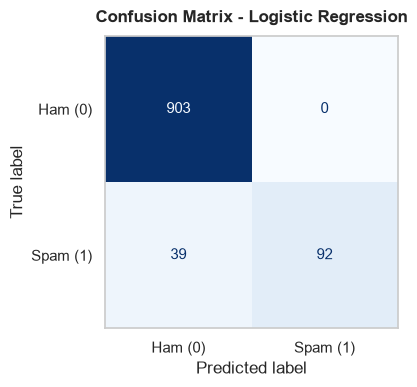

In [31]:
# Train Logistic Regression, evaluate on test set, print metrics, and plot confusion matrix
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(random_state=42)
lr_model.fit(X_train_tfidf, y_train)
lr_preds = lr_model.predict(X_test_tfidf)

lr_metrics = {
    'Model': 'Logistic Regression',
    'Accuracy': accuracy_score(y_test, lr_preds),
    'Precision': precision_score(y_test, lr_preds, pos_label=1),
    'Recall': recall_score(y_test, lr_preds, pos_label=1),
    'F1': f1_score(y_test, lr_preds, pos_label=1)
}

print(f"=== {lr_metrics['Model']} ===")
print(f"Accuracy:  {lr_metrics['Accuracy']:.4f}")
print(f"Precision: {lr_metrics['Precision']:.4f} (Spam)")
print(f"Recall:    {lr_metrics['Recall']:.4f} (Spam)")
print(f"F1-Score:  {lr_metrics['F1']:.4f} (Spam)\n")

fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, lr_preds,
    display_labels=['Ham (0)', 'Spam (1)'],
    cmap='Blues',
    ax=ax,
    colorbar=False
)
plt.title('Confusion Matrix - Logistic Regression', fontsize=12, fontweight='bold', pad=10)
plt.grid(False)
plt.tight_layout()
plt.show()

## 9. Model Comparison & Selection

In [32]:
# Compile and display side-by-side comparison table of all 3 models
comparison_df = pd.DataFrame([nb_metrics, svm_metrics, lr_metrics]).set_index('Model')
display(comparison_df.round(4))


,Accuracy,Precision,Recall,F1
Model,,,,
Multinomial Naive Bayes,0.9632,0.9895,0.7176,0.8319
Linear SVM (LinearSVC),0.9826,0.9748,0.8855,0.9280
Logistic Regression,0.9623,1.0000,0.7023,0.8251


### Best Model Selection & Analysis

**Best Overall Model:** **Linear SVM (`LinearSVC`)**

**Why Linear SVM is the best model:**
- **Highest Accuracy & F1-Score:** Linear SVM achieves the highest accuracy (**98.26%**) and F1-score (**0.9280**) among all three models.
- **Significantly Better Recall:** It catches **88.55%** (116 of 131) of spam messages, compared to only 71.76% for Naive Bayes and 70.23% for Logistic Regression.
- **Exceptional Precision:** With **97.48%** precision, it had only 3 false positives (legitimate messages classified as spam) out of 903 test ham messages.

While **Logistic Regression** achieved 100% precision (0 false positives), its lower recall (70.23%) means it misses nearly 30% of incoming spam messages. Thus, **Linear SVM** delivers the most robust and practical balance for real-world spam detection.

## 10. Save Best Model and Vectorizer

We serialize the fitted `TfidfVectorizer` and the best-performing `LinearSVC` model using `joblib` into the `model/` directory for production serving.

In [33]:
# Create model directory and serialize the fitted TF-IDF vectorizer and Linear SVM model using joblib
import os
import joblib

os.makedirs('model', exist_ok=True)
joblib.dump(tfidf, 'model/tfidf.joblib')
joblib.dump(svm_model, 'model/model.joblib')

print('Saved model artifacts successfully:')
print(f"- Vectorizer: model/tfidf.joblib ({os.path.getsize('model/tfidf.joblib'):,} bytes)")
print(f"- Classifier: model/model.joblib ({os.path.getsize('model/model.joblib'):,} bytes)")

Saved model artifacts successfully:
- Vectorizer: model/tfidf.joblib (140,164 bytes)
- Classifier: model/model.joblib (56,411 bytes)
